# Drone obstacles: learn MPC costs with SHAC

Learn to reach the origin while avoiding the obstacles from
[drone_obstacles.ipynb](../drone_obstacles.ipynb), using an MPC cost network trained with SHAC.

At each control step, solve the following MPC problem in the standard optimal control form
from the [TurboMPC paper](https://arxiv.org/pdf/2606.24039#page=2), with inequality slack **disabled**:

$$
\begin{aligned}
\min_{x,u}\quad
&\sum_{t=0}^{N-1}\ell_t^\theta(x_t,u_t,x_{t+1},u_{t+1})+\ell_N^\theta(x_N,u_N) \\
\text{subject to}\quad
&x_0=x_{\mathrm{init}}, \\
&f_t(x_t,u_t,x_{t+1},u_{t+1})=0, &&t=0,\ldots,N-1, \\
&\underline g_t\le g_t(x_t,u_t)\le\overline g_t, &&t=0,\ldots,N.
\end{aligned}
$$

For $x=(p,v)\in\mathbb R^6$ and $u\in\mathbb R^3$, the costs are
$$
\begin{aligned}
\ell_t^\theta &= x_t^\top Q_\theta x_t+u_t^\top R_\theta u_t
 +\tfrac12(u_{t+1}-u_t)^\top W(u_{t+1}-u_t), \\
\ell_N^\theta &= x_N^\top(Q_\theta+P_\theta)x_N+u_N^\top R_\theta u_N.
\end{aligned}
$$
The network predicts the **15 diagonal entries** of $Q_\theta,P_\theta,R_\theta$
from the current state and remaining episode time; $W=0.01I$ is fixed.
The equality $f_t=0$ enforces RK4 dynamics. The inequalities encode state bounds,
$-10\le u_t\le10$, and obstacle clearance
$\|p_t^{xy}-c_j\|_2\ge r_j+0.05+0.001$ m (5 cm planning buffer and 1 mm numerical offset).

The controller replans at **50 Hz** and holds each input for **0.02 s**.
Its prediction grid remains **20 intervals × 1 s**, giving a 20 s lookahead.
SHAC trains the cost network through the MPC controls and simulated trajectories.

## Imports

Install this checkout with `pip install -e '.[rl]'`. GPU execution also needs
CUDA-enabled JAX and PyTorch. Choose `DEVICE` before running; restart the kernel to change it.

In [1]:
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path
from time import perf_counter

DEVICE = "cuda"  # "cpu" or "cuda"
os.environ["JAX_PLATFORMS"] = DEVICE
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "examples/rl").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import Markdown, display
from examples.drone_utils import (
    DRONE_X0_BASE, OBS_CENTERS, OBS_RADII, generate_drone_x0, make_drone_config,
)
from turbompc.dynamics.integrators import predict_next_state
from examples.rl.env.drone import DroneProblem, DroneRuntime
from examples.rl.shac.shac import SHAC, SHACConfig
from examples.rl.util.networks import Actor, Critic
from examples.rl.util.training import load_checkpoint, save_checkpoint, seed_everything

%matplotlib inline

torch.set_num_threads(1)
if DEVICE == "cuda":
    if not torch.cuda.is_available() or any(d.platform != "gpu" for d in jax.devices()):
        raise RuntimeError("Both PyTorch and JAX must use CUDA.")
print(f"Torch: {DEVICE}; JAX: {jax.devices()}")

Torch: cuda; JAX: [CudaDevice(id=0)]


## RL task loss

Training starts are perturbations around the tutorial's initial state, sampled by
`generate_drone_x0`. For the next state $x^+=(p^+,v^+)$, use the fixed task cost
$$
\begin{aligned}
h_j(x^+) &= \max\!\left(0,\ r_j+0.03-\|p^{xy,+}-c_j\|_2\right), \\
\ell_{\mathrm{task}}(x^+,u) &=
\|p^+\|^2+0.1\|v^+\|^2+0.01\|u\|^2
+\sqrt{1+\|p^+\|^2/0.1^2}-1+10^5\sum_j h_j(x^+)^2, \\
\Phi(x_T) &= 1000\|p_T\|^2+100\|v_T\|^2.
\end{aligned}
$$
The smooth goal term gives a stronger gradient near the **0.1 m arrival tolerance**;
the terminal cost penalizes remaining position and velocity errors. The squared hinge
penalty is zero outside each obstacle's **3 cm clearance band**.

RL minimizes the expected integrated task cost plus the terminal cost,
$$\mathcal L_{\mathrm{RL}}(\theta)=\mathbb E\!\left[
\sum_{t=0}^{T-1}\Delta t_{\mathrm{control}}\,
\ell_{\mathrm{task}}(x_{t+1},u_t)+\Phi(x_T)\right].$$
Use reward $r_t=-\Delta t_{\mathrm{control}}\ell_{\mathrm{task}}(x_{t+1},u_t)$,
subtract $\Phi(x_T)$ at the episode end, and set $\gamma=1$.
SHAC uses short differentiable rollouts with a target critic for the remaining return.
These reward weights stay fixed while the MPC cost network is trained.

In [2]:
UPDATES = 100
NUM_ENVS = 128
MPC_HORIZON = 20
CONTROL_DT = 0.02
MPC_DT = 1.0
EPISODE_SECONDS = 30.0
EPISODE_STEPS = round(EPISODE_SECONDS / CONTROL_DT)
ROLLOUT_STEPS = 40
SEED = 0
VALIDATION_SEED = 100_000
TEST_SEED = 300_000
GOAL_TOLERANCE = 0.1

reward_weights = {
    "state": [1, 1, 1, 0.1, 0.1, 0.1],
    "control": [0.01] * 3,
    "goal": 1.0,
    "goal_radius": GOAL_TOLERANCE,
    "terminal_state": [1000.0] * 3 + [100.0] * 3,
    "obstacle": 100000.0,
}
seed_everything(SEED)
RUN_DIR = ROOT / "results/rl/drone_obstacle_training_50hz"
RUN_DIR.mkdir(parents=True, exist_ok=True)

## MPC setup

Use **one SQP iteration per control step**, **no inequality slack**, and control
bounds **−10 ≤ u ≤ 10**. The first warm start follows the corridor reference;
later solves shift the previous trajectory by the elapsed 0.02 s. Initialization uses no extra MPC solves.

Both nominal and trained MPC plan with a **5 cm obstacle buffer**. Evaluation measures
clearance against the original physical radii.

In [3]:
task = make_drone_config(
    horizon=MPC_HORIZON, dt=MPC_DT, discretization_scheme=2,
    use_slack=False, slack_weight=0.0, obs_radii=OBS_RADII,
    sqp_iter=1, sqp_tol=1e-5, admm_tol=1e-5, admm_max_iter=1000,
)
solver_config = {
    **task.solver_params,
    "constraint_handling": "log_barrier",
    "log_barrier_kappa": 1e-4,
    "forward_backend": "admm_fused_cudss" if DEVICE == "cuda" else "admm_jax_loop_jax_dense",
    "backward_backend": "direct_cudss_ffi" if DEVICE == "cuda" else "direct_jax_dense",
}
problem = DroneProblem(task, planning_margin=0.05)
runtime = DroneRuntime(
    problem, solver_config, device=DEVICE, episode_steps=EPISODE_STEPS,
    control_dt=CONTROL_DT, reward_weights=reward_weights,
    finite_horizon=True, reward_clearance=0.03,
)

## SHAC learner

The actor is a two-layer, 64-unit ReLU network that predicts 15 diagonal MPC cost weights.
Its output layer starts at zero, so the initial policy uses nominal MPC costs.
The critic has two 64-unit tanh layers and also starts with zero output.
Both observe the six-state vector plus the fraction of episode time remaining.

Episodes last 30 s (1,500 control steps); each differentiable rollout is 40 steps
(0.8 s). Use `gamma = 1`, with critic bootstrapping at rollout boundaries and zero
bootstrap at episode ends.

Decay the existing output-layer bias learning rate from 0.05 to 0.005 over 100
updates, sharing its updates across the three spatial axes within each cost group.
Use 0.0001 for the other actor parameters. Fit the critic for 8 passes per
update. Scale rewards by 0.01 during optimization; reported task costs use the
original units.

### Exploration noise

During training, add independent Gaussian noise to the first MPC control, then clip:
$$u_t=\operatorname{clip}(u_t^{\mathrm{MPC}}+\epsilon_t,u_{\min},u_{\max}),
\qquad\epsilon_t\sim\mathcal N(0,\operatorname{diag}(\sigma^2)).$$
For $(F_x,F_y,F_z)$, use $\sigma=(0.001,0.001,0.001)$ in the model's control units.
The standard deviations stay fixed (`learn_sigma=False`). Validation and evaluation
disable this noise; initial-state perturbations are sampled separately.

In [4]:
actor_config = {
    "hidden_sizes": [64, 64], "activation": "relu", "output_gain": 0.0,
    "initial_sigma": [0.001] * 3, "learn_sigma": False,
    "network_learning_rate": 0.0001,
}
critic_config = {"hidden_sizes": [64, 64], "activation": "tanh", "output_gain": 0.0}
actor = Actor(runtime.observation_dim, problem.cost_dim, 3, actor_config, dtype=runtime.dtype).to(DEVICE)
critic = Critic(runtime.observation_dim, critic_config, dtype=runtime.dtype).to(DEVICE)
shac_config = SHACConfig(
    seed=SEED, num_envs=NUM_ENVS, training_horizon=ROLLOUT_STEPS,
    total_updates=UPDATES, gamma=1.0, actor_learning_rate=0.05,
    anneal_lr=True, final_learning_rate=0.005,
    normalize_returns=False, reward_scale=0.01, target_critic_alpha=0.9,
    critic_iterations=8, critic_minibatches=4,
)
learner = SHAC(runtime, actor, critic, shac_config)
output_bias = actor.network[-1].bias
# Share the existing bias updates across x, y, z within each cost group.
output_bias.register_hook(
    lambda gradient: gradient.reshape(5, 3).sum(dim=1).repeat_interleave(3)
)
learner.actor_optimizer = torch.optim.Adam(
    [{"params": [output_bias]},
     {"params": [p for p in actor.parameters() if p is not output_bias and p.requires_grad],
      "lr": actor_config["network_learning_rate"]}],
    lr=shac_config.actor_learning_rate, betas=shac_config.adam_betas,
)

## Training

### Validation helper

Run a full episode without exploration or resets. Arrival is the first time the drone
stays within 0.1 m of the goal for the rest of the episode; unsuccessful arrivals count as 30 s.
Check physical clearance at control states and interval midpoints (every 0.01 s).

In [5]:
dynamics_params = jax.tree.map(
    lambda value: value[0], task.problem_params["dynamics_state_dot_params"]
)
fractions = jnp.linspace(0.0, 1.0, 3)
intermediate_states = jax.jit(jax.vmap(
    lambda fraction, x, u: predict_next_state(
        task.dynamics, CONTROL_DT * fraction, 2, dynamics_params, x, u
    ),
    in_axes=(0, None, None),
))

In [6]:
@torch.no_grad()
def evaluate(initial_states, *, learned):
    learner.actor.eval()
    batch_size = len(initial_states)
    state = runtime.reset(batch_size, SEED, initial_states=initial_states)
    fixed_costs = state.x.new_zeros((batch_size, problem.cost_dim))
    states, controls, rewards, valid = [state.x], [], [], []
    for _ in range(EPISODE_STEPS):
        costs = (
            learner.actor(runtime.observe(state)) if learned
            else fixed_costs
        )
        policy = runtime.policy(costs, state, retain=False)
        action = runtime.squash_action(policy.mean)
        transition = runtime.step(state, action, policy)
        state = transition.state
        states.append(state.x)
        controls.append(action)
        rewards.append(transition.reward)
        valid.append(transition.valid)

    states, controls, rewards, valid = (
        torch.stack(values).cpu().numpy() for values in (states, controls, rewards, valid)
    )
    dense = np.asarray(intermediate_states(
        fractions, jnp.asarray(states[:-1]), jnp.asarray(controls)
    ))
    clearance = np.linalg.norm(dense[..., None, :2] - OBS_CENTERS, axis=-1) - OBS_RADII
    near_goal = np.linalg.norm(states[..., :3], axis=-1) < GOAL_TOLERANCE
    settled = np.logical_and.accumulate(near_goal[::-1], axis=0)[::-1]
    arrival = np.where(settled.any(axis=0), settled.argmax(axis=0), EPISODE_STEPS)
    return {
        "states": states,
        "dense": dense,
        "costs": -np.sum(rewards, axis=0),
        "arrival": CONTROL_DT * arrival,
        "goal_distance": np.linalg.norm(states[-1, :, :3], axis=-1),
        "effort": CONTROL_DT * np.square(controls).sum(axis=(0, 2)),
        "clearance": clearance.min(axis=(0, 1, 3)),
        "valid": np.all(valid, axis=0),
    }

In [7]:
def summarize(result, rows=slice(None)):
    return {
        "cost": float(result["costs"][rows].mean()),
        "success_rate": float((
            (result["goal_distance"][rows] < GOAL_TOLERANCE)
            & (result["clearance"][rows] >= 0) & result["valid"][rows]
        ).mean()),
        "arrival": float(result["arrival"][rows].mean()),
        "goal_distance": float(result["goal_distance"][rows].mean()),
        "effort": float(result["effort"][rows].mean()),
        "collision_rate": float((result["clearance"][rows] < 0).mean()),
        "min_clearance": float(result["clearance"][rows].min()),
        "solver_failure_rate": float((~result["valid"][rows]).mean()),
    }

### Nominal baseline

Use the same 64 validation starts throughout training. This baseline uses the tutorial's
fixed cost weights and the same dynamics, constraints, and warm-start rules as the learned policy.
Compute nominal validation and test trajectories together in one GPU batch; only the
validation rows are used for checkpoint selection.

In [8]:
validation_starts = generate_drone_x0(64, VALIDATION_SEED)
test_starts = np.vstack((DRONE_X0_BASE, generate_drone_x0(64, TEST_SEED)))
nominal = evaluate(np.vstack((validation_starts, test_starts)), learned=False)
split = len(validation_starts)
nominal_validation = summarize(nominal, slice(0, split))
nominal_test = {
    key: value[..., split:, :] if key in ("states", "dense") else value[split:]
    for key, value in nominal.items()
}
print("Nominal MPC:", nominal_validation)

Nominal MPC: {'cost': 448.87782546216977, 'success_rate': 0.0, 'arrival': 30.0, 'goal_distance': 0.28144672481864097, 'effort': 2.761741264727255, 'collision_rate': 0.0, 'min_clearance': 0.03718606539720559, 'solver_failure_rate': 0.0}


### Training loop

Run exactly 100 updates, each collecting 0.8 s per environment and training the actor and critic.
Every 50 updates, validate on the same starts. Eligible checkpoints must have no solver
failures and at least **1 cm sampled physical clearance**. Rank them by goal success rate,
then earlier arrival, then lower task cost. Keep nominal MPC if no eligible policy improves
on it. After all 100 updates, load the best validation checkpoint for the test comparison.
Rerun from the top for a fresh policy.

In [9]:
def validation_rank(score):
    return score["success_rate"], -score["arrival"], -score["cost"]

history = []
validation = [dict(update=0, **nominal_validation)]
best_score, selected_update = nominal_validation, 0
save_checkpoint(learner, RUN_DIR / "checkpoint.pt")
started = perf_counter()
for update in range(1, UPDATES + 1):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    iteration_started = perf_counter()
    rollout = learner.collect()
    metrics = learner.update(rollout)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    history.append({
        "update": update,
        "iteration_seconds": perf_counter() - iteration_started,
        "reward_mean": rollout.metrics["rollout/reward_mean"],
        "actor_gradient": metrics["train/actor_gradient_norm"],
        "critic_loss": metrics["train/value_loss"],
    })
    if update % 5 == 0:
        print(
            f"{update:3d}/{UPDATES}: training reward={history[-1]['reward_mean']:.4f}, "
            f"time={history[-1]['iteration_seconds']:.2f} s"
        )
    if update % 50 == 0 or update == UPDATES:
        score = summarize(evaluate(validation_starts, learned=True))
        validation.append(dict(update=update, **score))
        feasible = score["min_clearance"] >= 0.01 and score["solver_failure_rate"] == 0
        if feasible and validation_rank(score) > validation_rank(best_score):
            best_score, selected_update = score, update
            save_checkpoint(learner, RUN_DIR / "checkpoint.pt")
        print(
            f"{update:3d}/{UPDATES}: validation cost={score['cost']:.3f}, "
            f"success={score['success_rate']:.1%}, arrival={score['arrival']:.1f} s, "
            f"collisions={score['collision_rate']:.1%}"
        )


  5/100: training reward=-0.4259, time=5.57 s
 10/100: training reward=-0.3780, time=5.65 s
 15/100: training reward=-0.3036, time=5.67 s
 20/100: training reward=-0.2177, time=5.45 s
 25/100: training reward=-0.1380, time=5.31 s
 30/100: training reward=-0.0742, time=4.68 s
 35/100: training reward=-0.0307, time=4.49 s
 40/100: training reward=-0.4240, time=5.47 s
 45/100: training reward=-0.3475, time=5.69 s
 50/100: training reward=-0.2318, time=5.25 s
 50/100: validation cost=201.617, success=100.0%, arrival=19.5 s, collisions=0.0%
 55/100: training reward=-0.1179, time=5.15 s
 60/100: training reward=-0.0401, time=0.57 s
 65/100: training reward=-0.0066, time=0.52 s
 70/100: training reward=-0.0035, time=0.59 s
 75/100: training reward=-0.0937, time=0.51 s
 80/100: training reward=-0.3741, time=5.83 s
 85/100: training reward=-0.2351, time=5.21 s
 90/100: training reward=-0.1054, time=5.05 s
 95/100: training reward=-0.0279, time=0.49 s
100/100: training reward=-0.0048, time=0.49 

### Training outputs

`final_checkpoint.pt` contains the last update; `checkpoint.pt` contains the policy
selected using validation only. Use the selected policy for the test comparison below.

In [10]:
save_checkpoint(learner, RUN_DIR / "final_checkpoint.pt")
load_checkpoint(learner, RUN_DIR / "checkpoint.pt")
print(f"Completed {len(history)} updates; selected update {selected_update} using validation only.")
settings = dict(
    device=DEVICE, mpc_horizon=MPC_HORIZON, mpc_dt=MPC_DT,
    control_dt=CONTROL_DT, episode_seconds=EPISODE_SECONDS, use_slack=False,
    planning_margin=0.05, episode_steps=EPISODE_STEPS,
    actor=actor_config, critic=critic_config, shac=asdict(shac_config),
    solver=solver_config, reward_weights=reward_weights,
    reward_clearance=0.03, finite_horizon=True, goal_tolerance=GOAL_TOLERANCE,
    validation_seed=VALIDATION_SEED, test_seed=TEST_SEED,
    selected_update=selected_update, completed_updates=len(history),
)
for name, data in (("settings", settings), ("history", history), ("validation", validation)):
    (RUN_DIR / f"{name}.json").write_text(json.dumps(data, indent=2, allow_nan=False))
print(f"Training + validation including compilation: {perf_counter() - started:.1f} s")

Completed 100 updates; selected update 100 using validation only.
Training + validation including compilation: 558.5 s


## Evaluation

Compare nominal and trained MPC on **64 separate test starts**, using identical initial
states and no exploration. Both policies share the dynamics, constraints, solver settings,
and warm-start rules.

Reserve row 0 for the tutorial's original start in the trajectory plot; exclude it from the table.

In [11]:
results = {
    "Nominal MPC": nominal_test,
    "Trained MPC": evaluate(test_starts, learned=True),
}
summary = {name: summarize(result, slice(1, None)) for name, result in results.items()}
(RUN_DIR / "comparison.json").write_text(json.dumps(summary, indent=2, allow_nan=False))
np.savez_compressed(
    RUN_DIR / "evaluation.npz", initial_states=test_starts,
    **{
        f"{name.split()[0].lower()}_{key}": value
        for name, result in results.items() for key, value in result.items()
    },
)

## Results

### Metrics

Report task cost, goal success rate, arrival time, goal distance, control effort,
clearance, and failures over the 64 test starts. Success requires final goal distance
below 0.1 m, no sampled collision, and no solver failure.


In [12]:
labels = {
    "cost": "Mean task cost ↓",
    "success_rate": "Goal success fraction ↑",
    "arrival": "Arrival time (s) ↓",
    "goal_distance": "Final goal distance (m) ↓",
    "effort": "Control effort ∫‖u‖² dt",
    "collision_rate": "Collision fraction ↓",
    "min_clearance": "Minimum obstacle clearance (m) ↑",
    "solver_failure_rate": "Solver failure fraction ↓",
}
lines = ["| Metric | Nominal MPC | Trained MPC |", "|---|---:|---:|"]
for key, label in labels.items():
    lines.append(
        f"| {label} | {summary['Nominal MPC'][key]:.4f} "
        f"| {summary['Trained MPC'][key]:.4f} |"
    )
display(Markdown("\n".join(lines)))

| Metric | Nominal MPC | Trained MPC |
|---|---:|---:|
| Mean task cost ↓ | 452.3434 | 179.7712 |
| Goal success fraction ↑ | 0.0000 | 1.0000 |
| Arrival time (s) ↓ | 30.0000 | 17.3297 |
| Final goal distance (m) ↓ | 0.2802 | 0.0431 |
| Control effort ∫‖u‖² dt | 2.3991 | 14.3493 |
| Collision fraction ↓ | 0.0000 | 0.0000 |
| Minimum obstacle clearance (m) ↑ | 0.0393 | 0.0408 |
| Solver failure fraction ↓ | 0.0000 | 0.0000 |

### Plots

Show validation task cost, mean goal distance over the 64 test starts, and the trajectory
from the tutorial's original start. The trajectory plot marks the start (triangle), goal
(star), and physical obstacle radii.

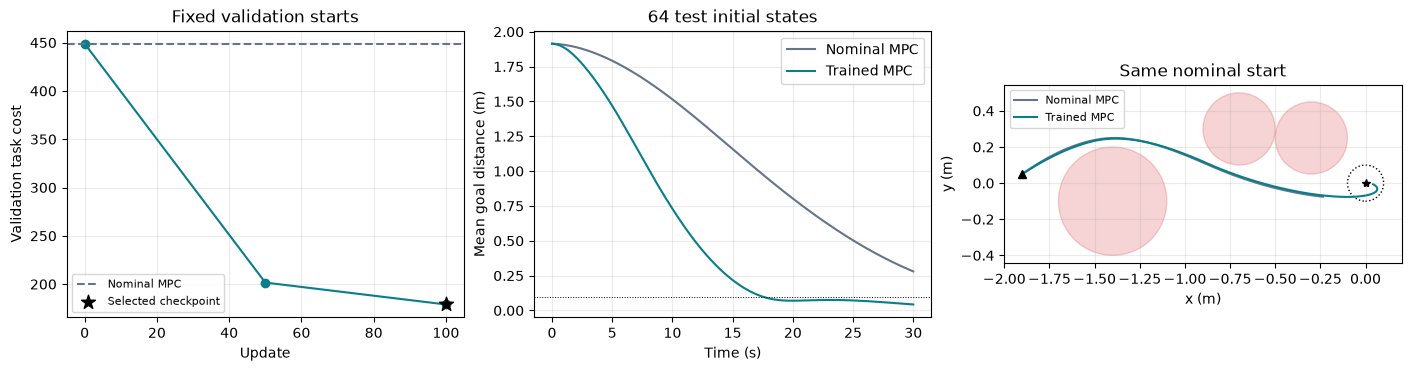

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout="constrained")
axes[0].plot([r["update"] for r in validation], [r["cost"] for r in validation], "o-", color="#087e8b")
axes[0].axhline(nominal_validation["cost"], color="#64748b", ls="--", label="Nominal MPC")
axes[0].set(xlabel="Update", ylabel="Validation task cost", title="Fixed validation starts")
axes[0].scatter(
    selected_update, best_score["cost"], marker="*", s=110, color="black",
    label="Selected checkpoint", zorder=4,
)
rejected = [r for r in validation if r["min_clearance"] < 0.01 or r["solver_failure_rate"] > 0]
if rejected:
    axes[0].scatter(
        [r["update"] for r in rejected], [r["cost"] for r in rejected],
        marker="x", color="tab:red", label="Clearance/failure check failed",
    )
axes[0].legend(fontsize=8)
for (name, result), color in zip(results.items(), ("#64748b", "#087e8b")):
    distance = np.linalg.norm(result["states"][:, 1:, :3], axis=-1).mean(axis=1)
    axes[1].plot(CONTROL_DT * np.arange(EPISODE_STEPS + 1), distance, color=color, label=name)
    trajectory = result["dense"][:, :, 0].swapaxes(0, 1).reshape(-1, 6)
    axes[2].plot(trajectory[:, 0], trajectory[:, 1], color=color, label=name)
axes[1].axhline(GOAL_TOLERANCE, color="black", lw=0.7, ls=":")
axes[1].set(xlabel="Time (s)", ylabel="Mean goal distance (m)", title="64 test initial states")
axes[1].legend()
for center, radius in zip(OBS_CENTERS, OBS_RADII):
    axes[2].add_patch(Circle(center, radius, color="tab:red", alpha=0.2))
axes[2].plot(*DRONE_X0_BASE[:2], "k^")
axes[2].plot(0, 0, "k*")
axes[2].add_patch(Circle((0, 0), GOAL_TOLERANCE, fill=False, ls=":", color="black"))
axes[2].set(xlabel="x (m)", ylabel="y (m)", aspect="equal", title="Same nominal start")
axes[2].legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.grid(alpha=0.25)
fig.savefig(RUN_DIR / "comparison.png", dpi=160)
plt.show()